# Module 7A — อ่านกราฟและตรวจสิ่งที่ AI เลือก

**เป้าหมาย:** เห็นว่ากราฟคำนวณและซ่อนอะไร เปรียบเทียบรูปแบบการนำเสนอ และตรวจความเสี่ยงก่อนแก้ความสวย
โค้ดถูกซ่อนเป็นค่าเริ่มต้น เปิดดูได้เมื่อต้องการ audit

## อ่านเพิ่ม

- Kieran Healy, *Data Visualization: A Practical Introduction* (Princeton University Press, 2018)
- Chun-houh Chen, Wolfgang Härdle และ Antony Unwin (บรรณาธิการ), *Handbook of Data Visualization* (Springer, 2008)

ตัวอย่างและข้อมูลทั้งหมดใน notebook สร้างใหม่เพื่อการสอน

เนื้อหานี้ไม่ทดแทนวิชาสถิติหรือระเบียบวิธีวิจัย กราฟที่ดูสมเหตุสมผลอาจยังตั้งอยู่บน
model, sampling หรือ causal claim ที่ผิดได้

## 0. เครื่องมือฟรีที่ใช้

Notebook นี้เป็นแบบ standalone เซลล์ setup ถัดไปจะตรวจทั้งการมีอยู่และรุ่นของ package
แล้วติดตั้ง core stack ที่ขาดหรือเก่าเกินไปให้ครบใน Python environment ของ kernel ปัจจุบัน
จึงไม่สมมติว่าเครื่องเคยติดตั้ง package จากบทก่อนหน้า

Setup จะเตรียมฟอนต์ Sarabun ให้กราฟภาษาไทยอัตโนมัติ ไม่ต้องติดตั้งเอง

| งาน | ไลบรารี | เหตุผลที่อยู่ในคลาส |
|---|---|---|
| ภาพนิ่งและควบคุมรายละเอียด | Matplotlib | เป็นฐานที่กว้างและส่งออก SVG/PDF ได้ |
| distribution/statistical graphics | Seaborn | ทำ layer ของ raw points, violin, interval ได้เร็ว |
| hover/zoom/filter | Plotly Express | สร้าง interactive HTML แบบ standalone ได้ |
| linked views/brushing | Altair | grammar ชัด เหมาะกับการอธิบาย encoding และ interaction |

ไลบรารีไม่ใช่ผู้ตัดสินความถูกต้อง—มันเพียงทำตามข้อมูลและ parameter ที่ได้รับ

### เครื่องมืออื่นที่ควรรู้จัก

คลาสนี้ไม่จำเป็นต้องติดตั้งทุกตัว แต่ควรรู้ว่ามีทางเลือกสำหรับงานเฉพาะทาง:

- [deck.gl](https://deckgl.readthedocs.io/en/latest/) — เหมาะกับแผนที่หรือข้อมูลเชิงพื้นที่
  ปริมาณมากที่ต้องใช้การเร่งผลด้วย WebGL
- [Lets-Plot](https://lets-plot.org/) — แนว grammar of graphics สำหรับสร้างภาพนิ่งและ
  interactive plot โดยเขียน specification เป็นระบบ
- [Folium](https://python-visualization.github.io/folium/latest/) — ใช้ Python สร้างแผนที่
  interactive บนฐาน Leaflet เหมาะกับ marker, polygon, choropleth และ layer control

ทั้งสามตัวเป็น **ทางเลือกตามโจทย์** ไม่ใช่รายการ package ที่ทุกคนต้องมี หากคำถามวิจัยไม่มีมิติ
เชิงพื้นที่ การเพิ่มแผนที่อาจทำให้ซับซ้อนขึ้นโดยไม่ได้เพิ่มคำตอบ

ขั้นตอน Colab, Prompt และ workflow อยู่ใน
[Module 7 Workflow & Prompt Card](../templates/module-07-visualization-workflow-and-prompts.md)

In [1]:
# Standalone bootstrap for a fresh local environment or Google Colab.
# It checks package versions, then installs every missing/incompatible core dependency.
from importlib import invalidate_caches
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import subprocess
import sys

def ensure_packaging():
    try:
        from packaging.specifiers import SpecifierSet
        return SpecifierSet
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "--disable-pip-version-check", "--quiet", "packaging>=24,<27",
        ])
        invalidate_caches()
        from packaging.specifiers import SpecifierSet
        return SpecifierSet

SpecifierSet = ensure_packaging()
required = {
    "numpy": ">=1.26,<3",
    "pandas": ">=2.1,<3",
    "matplotlib": ">=3.8,<4",
    "seaborn": ">=0.13,<0.14",
    "plotly": ">=5.20,<8",
    "altair": ">=5.2,<7",
}
to_install = []
for distribution, constraint in required.items():
    try:
        installed = version(distribution)
    except PackageNotFoundError:
        installed = None
    if installed is None or installed not in SpecifierSet(constraint):
        to_install.append(f"{distribution}{constraint}")

if to_install:
    print("Installing Module 7 core packages:", ", ".join(to_install))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--disable-pip-version-check", "--upgrade-strategy", "only-if-needed",
        *to_install,
    ])
    invalidate_caches()
else:
    print("Module 7 core packages already satisfy the supported versions.")

verified = {name: version(name) for name in required}
print("Python environment ready.")
print("Verified:", verified)

Module 7 core packages already satisfy the supported versions.
Python environment ready.
Verified: {'numpy': '2.2.6', 'pandas': '2.3.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'plotly': '7.0.0', 'altair': '6.2.2'}


In [2]:
import sys
from pathlib import Path

import altair as alt
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import plotly.io as pio
import seaborn as sns

SEED = 20261110
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})
alt.data_transformers.disable_max_rows()
pio.renderers.default = "notebook"

versions = pd.Series({
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": mpl.__version__,
    "seaborn": sns.__version__,
    "plotly": plotly.__version__,
    "altair": alt.__version__,
}, name="version")
versions.to_frame()

,version
python,3.10.19
pandas,2.3.3
numpy,2.2.6
matplotlib,3.10.8
seaborn,0.13.2
plotly,7.0.0
altair,6.2.2


In [3]:
# Prepare a verified Thai font for this kernel; no system-wide installation is needed.
import hashlib
from urllib.request import urlopen

import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font

FONT_BASE_URL = "https://urban.cpe.ku.ac.th/ai-for-research/downloads/fonts/"
FONT_SPECS = {
    "Sarabun-Regular.ttf": "226d4f368fbc0457990ddef2692679badfd2c1a4e89e5ac4d43c10ba7743b2f1",
    "Sarabun-Bold.ttf": "d38308ca27d067b9a1b79006337c1f9a66c29aa016d96a9d88d3801da7fa83b9",
}
FONT_DIRS = [
    Path("fonts"),
    Path("../fonts"),
    Path("course-materials/module-07/fonts"),
    Path.home() / ".cache" / "ai-for-research" / "module-07" / "fonts",
]

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def verified_font_path(filename, expected_sha256):
    for directory in FONT_DIRS:
        candidate = directory / filename
        if candidate.is_file() and sha256_file(candidate) == expected_sha256:
            return candidate

    target_dir = FONT_DIRS[-1]
    target_dir.mkdir(parents=True, exist_ok=True)
    target = target_dir / filename
    temporary = target.with_suffix(target.suffix + ".download")
    try:
        with urlopen(FONT_BASE_URL + filename, timeout=30) as response:
            if not response.geturl().startswith(FONT_BASE_URL):
                raise RuntimeError("Thai-font download left the approved course URL.")
            content = response.read(2 * 1024 * 1024 + 1)
        if len(content) > 2 * 1024 * 1024 or hashlib.sha256(content).hexdigest() != expected_sha256:
            raise RuntimeError("Thai-font download failed verification.")
        temporary.write_bytes(content)
        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)
    return target

font_paths = [verified_font_path(name, digest) for name, digest in FONT_SPECS.items()]
for font_path in font_paths:
    font_manager.fontManager.addfont(font_path)

font_name = font_manager.FontProperties(fname=str(font_paths[0])).get_name()
if font_name != "Sarabun":
    raise RuntimeError(f"Unexpected Thai font family: {font_name}")

thai_glyph_probe = (
    "กขฃคฅฆงจฉชซฌญฎฏฐฑฒณดตถทธนบปผฝพฟภมยรลวศษสหฬอฮ"
    "ะาำิีึืุูเแโใไๅๆฯ่้๊๋์ํ๐๑๒๓๔๕๖๗๘๙"
)
for font_path in font_paths:
    charmap = FT2Font(str(font_path)).get_charmap()
    missing = [character for character in thai_glyph_probe if ord(character) not in charmap]
    if missing:
        raise RuntimeError(f"Sarabun is missing required Thai glyphs: {missing}")

fallback_path = Path(font_manager.findfont(
    font_manager.FontProperties(family="DejaVu Sans"), fallback_to_default=False
))
combined_charmap = set().union(
    *(set(FT2Font(str(path)).get_charmap()) for path in [font_paths[0], fallback_path])
)
symbol_glyph_probe = "−–—•±×÷≤≥≈°℃µαβγΔ→←↔∞√"
missing_symbols = [character for character in symbol_glyph_probe if ord(character) not in combined_charmap]
if missing_symbols:
    raise RuntimeError(f"Font stack is missing required scientific glyphs: {missing_symbols}")

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Sarabun", "DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
print("Thai font ready: Sarabun")

Thai font ready: Sarabun


In [4]:
# Teaching data 1: three groups with exactly the same sample mean and SD.
n = 60
raw_shapes = {
    "Near-normal": rng.normal(size=n),
    "Bimodal": np.r_[rng.normal(-2.2, 0.35, n // 2), rng.normal(2.2, 0.35, n // 2)],
    "One outlier": np.r_[rng.normal(0, 0.25, n - 1), 8.0],
}

def same_summary(x, mean=50, sd=10):
    x = np.asarray(x, dtype=float)
    return mean + sd * (x - x.mean()) / x.std(ddof=1)

shape_df = pd.concat(
    [pd.DataFrame({"group": name, "value": same_summary(values)})
     for name, values in raw_shapes.items()],
    ignore_index=True,
)

# Teaching data 2: repeated sensor-calibration runs for the makeover.
methods = ["Baseline", "Robust fit", "Proposed"]
minutes = np.arange(0, 61, 5)
rows = []
for method in methods:
    for run in range(1, 25):
        humidity = rng.uniform(35, 85)
        for minute in minutes:
            base = {"Baseline": 8.0, "Robust fit": 6.4, "Proposed": 5.8}[method]
            decay = {"Baseline": 0.030, "Robust fit": 0.043, "Proposed": 0.060}[method]
            floor = {"Baseline": 2.7, "Robust fit": 2.0, "Proposed": 1.5}[method]
            drift = max(humidity - 65, 0) * {"Baseline": .045, "Robust fit": .025, "Proposed": .012}[method]
            error = floor + base * np.exp(-decay * minute) + drift + rng.normal(0, .55)
            rows.append((method, run, minute, humidity, max(error, .15)))
sensor_df = pd.DataFrame(rows, columns=["method", "run", "minute", "humidity", "error_ppm"])

assert np.allclose(shape_df.groupby("group")["value"].mean(), 50)
assert np.allclose(shape_df.groupby("group")["value"].std(), 10)
assert not sensor_df.isna().any().any()
print(f"shape_df: {shape_df.shape}; sensor_df: {sensor_df.shape}; seed={SEED}")

shape_df: (180, 2); sensor_df: (936, 5); seed=20261110


## ภาพไม่ได้มีไว้ตกแต่งผลลัพธ์เท่านั้น

ใช้ภาพเพื่อ **สำรวจ** โครงสร้างและค่าผิดปกติ, **debug** การนำเข้า/การรวมข้อมูล, **สื่อสาร** หลักฐาน และ
**สนับสนุนการตัดสินใจ** ภายใต้ข้อจำกัดของข้อมูล ในช่วงสำรวจควรลอง representation มากกว่าหนึ่งแบบแล้ว
บันทึกว่าสิ่งใดปรากฏหรือหายไป แต่ภาพสำหรับส่งมอบควรเหลือเฉพาะมุมมองที่ตอบคำถามชัดเจนและเป็นธรรม

## 1. เปิดคลาส: summary เหมือนกัน ไม่ได้แปลว่าข้อมูลเหมือนกัน

เริ่มจากข้อมูลสามกลุ่ม ถ้า AI สรุปเพียง mean และ SD เราจะเห็นอะไร—และไม่เห็นอะไร?

In [5]:
summary = shape_df.groupby("group")["value"].agg(n="size", mean="mean", sd="std")
summary.round(2)

,n,mean,sd
group,,,
Bimodal,60,50.0,10.0
Near-normal,60,50.0,10.0
One outlier,60,50.0,10.0


### ดูสถิติสรุปก่อน

กราฟแรกใช้ค่าเฉลี่ยเป็นความสูงของแท่ง และใช้ SD เป็นเส้น error bar ทั้งสามกลุ่มมีค่าเฉลี่ยและ SD
เท่ากันโดยตั้งใจ จึงเป็นตัวอย่างของกราฟที่คำนวณถูก แต่ยังอาจเล่าเรื่องของข้อมูลไม่ครบ

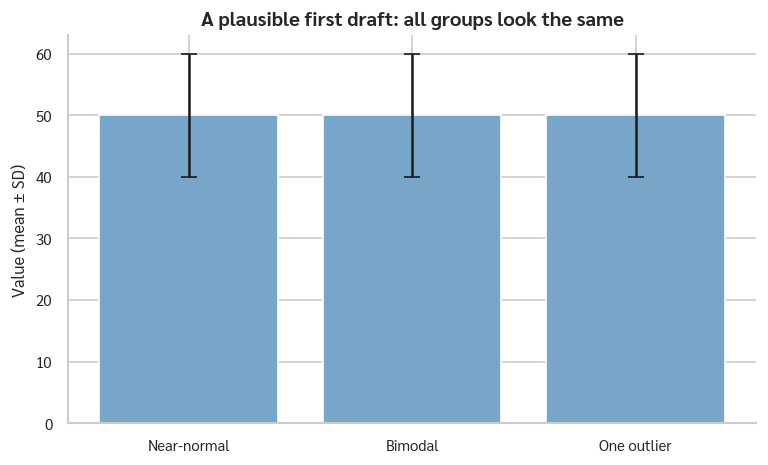

In [6]:
order = list(raw_shapes)
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.bar(order, summary.loc[order, "mean"], yerr=summary.loc[order, "sd"],
       color="#78A6C8", capsize=5)
ax.set(ylabel="Value (mean ± SD)", title="A plausible first draft: all groups look the same")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**หยุดก่อนรัน cell ถัดไป:** เขียนอย่างน้อย 3 สิ่งที่ bar chart นี้ซ่อนอยู่

- รูปร่างของ distribution?
- จำนวนและตำแหน่งของ observation?
- outlier หรือ subgroup?
- SD เป็น uncertainty ของ mean หรือ variability ของข้อมูล?

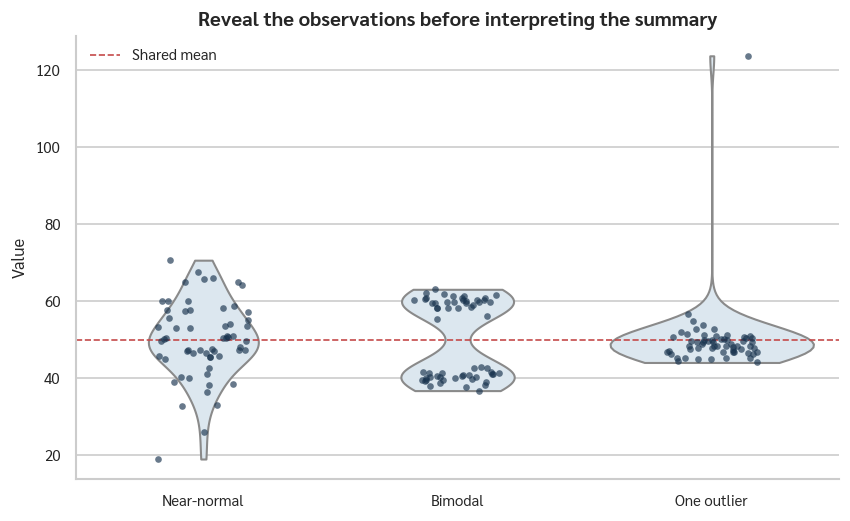

In [7]:
fig, ax = plt.subplots(figsize=(8.2, 4.8))
sns.violinplot(data=shape_df, x="group", y="value", order=order,
               inner=None, color="#D9E8F2", cut=0, ax=ax)
sns.stripplot(data=shape_df, x="group", y="value", order=order,
              color="#17324D", alpha=.65, jitter=.18, size=4, ax=ax)
ax.axhline(50, color="#C54A4A", lw=1, ls="--", label="Shared mean")
ax.set(title="Reveal the observations before interpreting the summary", xlabel="", ylabel="Value")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### หลักที่ต้องจำ

กราฟไม่ใช่ภาชนะกลาง ๆ แต่เป็นชุดการตัดสินใจ: เลือกข้อมูล → filter → transform/aggregate →
map เป็น position/length/color/shape → กำหนด scale → annotate → export

ผู้เรียนไม่จำเป็นต้องเก่งกว่าระบบในการ “เดาชื่อกราฟ” แต่ต้องตรวจชุดการตัดสินใจนี้ได้

### ข้อมูลเดียวกัน แต่ prose, table, bar และ line ทำหน้าที่ต่างกัน

ข้อความเหมาะกับการกล่าวค่าหลักไม่กี่ค่า ตารางเหมาะกับการค้นค่าที่แม่นยำ bar chart ช่วยเปรียบเทียบ
ณ ช่วงเวลาใดช่วงเวลาหนึ่ง และ line chart ช่วยติดตามการเปลี่ยนแปลงตามเวลา ไม่มีรูปแบบใดเป็นกลาง:
แต่ละแบบกำหนดสิ่งที่ผู้อ่านเห็นก่อน

,Year,Two-adult (%),One-adult (%),Other (%)
0,2000,68,28,4
1,2010,64,31,5
2,2020,61,34,5
3,2030,58,37,5


ข้อความย่อ: สัดส่วนครัวเรือนสองผู้ใหญ่ลดจาก 68% เป็น 58% ระหว่างปี 2000–2030


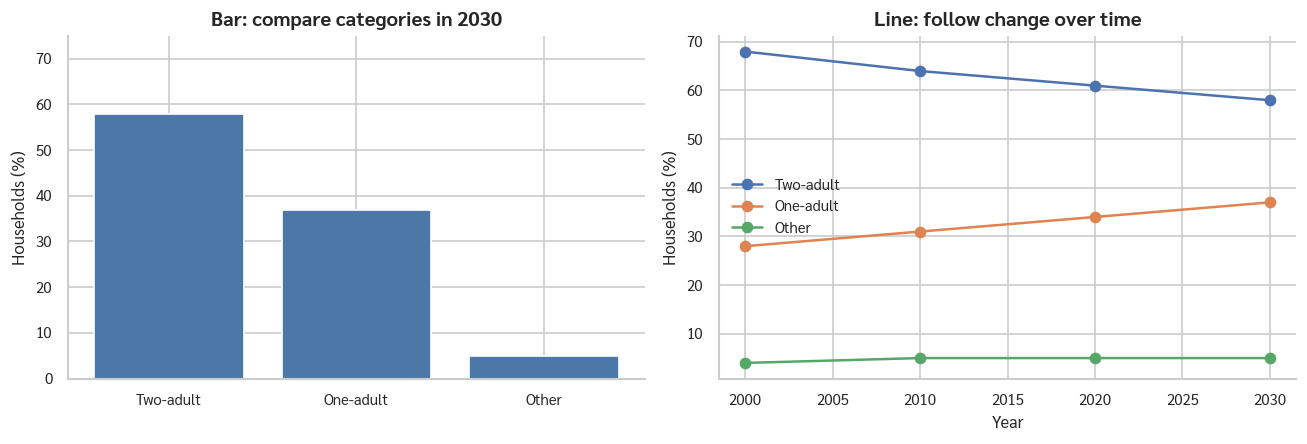

In [8]:
family_df = pd.DataFrame({
    "year": [2000, 2010, 2020, 2030],
    "two_adults": [68, 64, 61, 58],
    "one_adult": [28, 31, 34, 37],
    "other": [4, 5, 5, 5],
})
display(family_df.rename(columns={
    "year": "Year", "two_adults": "Two-adult (%)",
    "one_adult": "One-adult (%)", "other": "Other (%)"
}))
print("ข้อความย่อ: สัดส่วนครัวเรือนสองผู้ใหญ่ลดจาก 68% เป็น 58% ระหว่างปี 2000–2030")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
last = family_df.iloc[-1]
axes[0].bar(["Two-adult", "One-adult", "Other"],
            [last.two_adults, last.one_adult, last.other], color="#4C78A8")
axes[0].set(title="Bar: compare categories in 2030", ylabel="Households (%)", ylim=(0, 75))
for col, label in [("two_adults", "Two-adult"), ("one_adult", "One-adult"), ("other", "Other")]:
    axes[1].plot(family_df["year"], family_df[col], marker="o", label=label)
axes[1].set(title="Line: follow change over time", xlabel="Year", ylabel="Households (%)")
axes[1].legend(frameon=False)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### ตารางที่ดีช่วยให้ค้นและเปรียบเทียบค่า

ตารางไม่ใช่ข้อมูลที่เทลงในช่องเฉย ๆ ควรมีชื่อที่บอกประเด็น จัดกลุ่มและเรียงแถวตามงานอ่านค่า
ใช้ทศนิยมสม่ำเสมอ ใส่หน่วยในหัวตาราง และเน้นเฉพาะค่าที่ต้องการให้ค้นพบ

In [9]:
table_df = pd.DataFrame({
    "region": ["East", "North", "Central", "South"],
    "rate_2020": [7.8, 9.2, 6.4, 8.7],
    "rate_2025": [6.1, 7.0, 5.9, 8.2],
})
table_df["change_pp"] = table_df["rate_2025"] - table_df["rate_2020"]
table_df = table_df.sort_values("change_pp")
styled = (table_df.rename(columns={
    "region": "Region", "rate_2020": "2020 (%)", "rate_2025": "2025 (%)",
    "change_pp": "Change (percentage points)"})
    .style.format({"2020 (%)": "{:.1f}", "2025 (%)": "{:.1f}",
                   "Change (percentage points)": "{:+.1f}"})
    .background_gradient(subset=["Change (percentage points)"], cmap="Blues_r"))
styled

,Region,2020 (%),2025 (%),Change (percentage points)
1,North,9.2,7.0,-2.2
0,East,7.8,6.1,-1.7
2,Central,6.4,5.9,-0.5
3,South,8.7,8.2,-0.5


## 2. ก่อนเลือกกราฟ ให้ระบุงานอ่านค่า

| งานที่ผู้อ่านต้องทำ | จุดเริ่มต้นที่มักเหมาะ | สิ่งที่ต้องตรวจ |
|---|---|---|
| เปรียบเทียบค่าระหว่างกลุ่ม | dot/bar | baseline, order, uncertainty, n |
| ดูแนวโน้มตามเวลา | line | interval, missing time, smoothing, window |
| ดู distribution | dot/strip, histogram, ECDF, violin/box | bin/bandwidth, raw n, outliers |
| ดูความสัมพันธ์ | scatter/hexbin | overplotting, scale, confounders, causal overclaim |
| ดูองค์ประกอบของส่วนรวม | stacked bar/area | denominator, order, มากเกินไปหรือไม่ |
| ดูค่าประมาณและความไม่แน่นอน | interval/forest plot | interval type, reference, model |
| เทียบหลายกลุ่ม/หลายเวลา | small multiples | shared scale, panel order, empty panels |

ตารางนี้เป็น **จุดเริ่มตรวจ** ไม่ใช่กฎตายตัว รูปแบบต้องตรงคำถาม ผู้ชม และบริบท

### ตัวเลขเดียวกัน เมื่อเข้ารหัสต่างกัน

ภาพถัดไปนำตัวเลขชุดเดียวกันไปแสดงด้วยความยาว มุม และพื้นที่ ให้สังเกตว่า position/length
ช่วยการเปรียบเทียบค่าละเอียดได้ง่ายกว่า ขณะที่มุมและพื้นที่เหมาะกับการเห็นภาพรวมมากกว่า

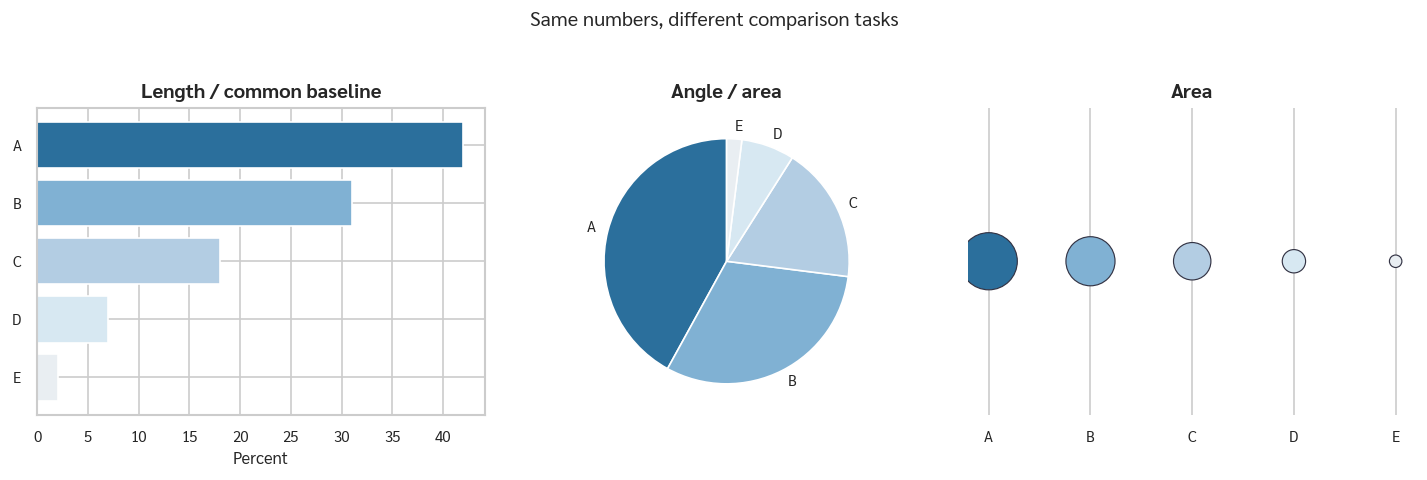

In [10]:
# The same values encoded with position/length, angle, and area.
cats = ["A", "B", "C", "D", "E"]
vals = np.array([42, 31, 18, 7, 2])
colors = ["#2B6F9C", "#80B1D3", "#B3CDE3", "#D7E8F2", "#E9EEF2"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].barh(cats[::-1], vals[::-1], color=colors[::-1])
axes[0].set_title("Length / common baseline")
axes[0].set_xlabel("Percent")
axes[1].pie(vals, labels=cats, colors=colors, startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Angle / area")
axes[2].scatter(cats, np.ones(len(cats)), s=vals * 28, c=colors,
                edgecolor="#334", linewidth=.7)
axes[2].set_title("Area")
axes[2].set_ylim(.7, 1.3)
axes[2].set_yticks([])
axes[2].spines[:].set_visible(False)
fig.suptitle("Same numbers, different comparison tasks", y=1.04)
fig.tight_layout()
plt.show()

**คำถามอภิปราย:** ภาพไหนช่วยให้ตอบว่า A มากกว่า B เท่าไรได้เร็วที่สุด? ภาพไหนทำให้ค่าขนาดเล็ก
หายไป? ถ้า AI เลือก pie chart ไม่จำเป็นต้องตอบทันทีว่า “ผิด” แต่ให้ถามว่า task ของผู้อ่านคืออะไร
และ encoding นี้ทำ task นั้นยากขึ้นหรือไม่

### Stacked bar และ 3D: ใช้ได้ แต่มีต้นทุนการอ่าน

stacked bar เหมาะกับส่วนประกอบที่รวมเป็น 100% แต่มีเพียงส่วนแรกที่มี baseline ร่วม ส่วนอื่นเปรียบเทียบ
ข้ามแท่งได้ยาก ส่วนมิติที่สามซึ่งไม่มีตัวแปรรองรับทำให้ perspective และพื้นที่บังกันโดยไม่เพิ่มข้อมูล

/tmp/ipykernel_119449/2041360596.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); plt.show()


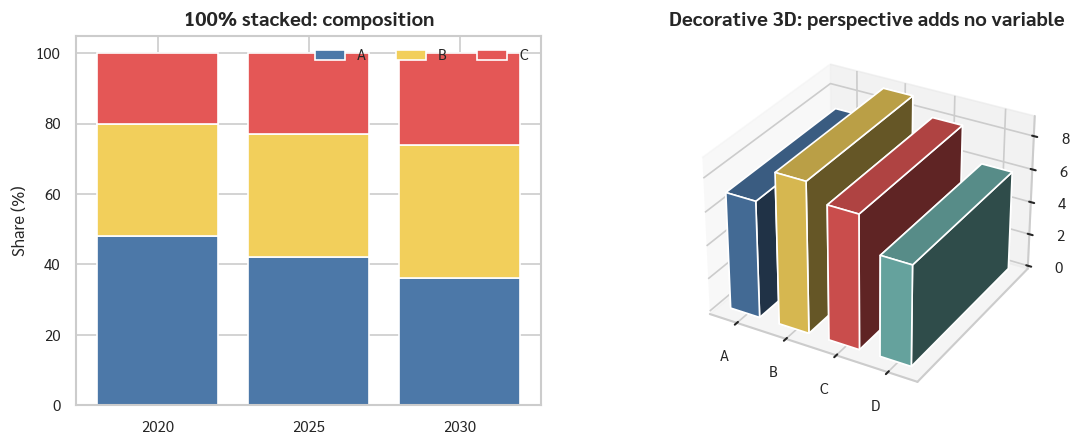

In [11]:
mix = pd.DataFrame({"year": [2020, 2025, 2030], "A": [48, 42, 36], "B": [32, 35, 38], "C": [20, 23, 26]})
fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(121)
bottom = np.zeros(len(mix))
for name, color in zip(["A", "B", "C"], ["#4C78A8", "#F2CF5B", "#E45756"]):
    ax1.bar(mix["year"].astype(str), mix[name], bottom=bottom, label=name, color=color)
    bottom += mix[name].to_numpy()
ax1.set(title="100% stacked: composition", ylabel="Share (%)")
ax1.legend(frameon=False, ncol=3)

ax2 = fig.add_subplot(122, projection="3d")
xpos = np.arange(4); values = np.array([7, 9, 8, 6])
ax2.bar3d(xpos, np.zeros(4), np.zeros(4), .6, .6, values,
          color=["#4C78A8", "#F2CF5B", "#E45756", "#72B7B2"], shade=True)
ax2.set_xticks(xpos + .3, ["A", "B", "C", "D"])
ax2.set_yticks([]); ax2.set_zlabel("Value")
ax2.set_title("Decorative 3D: perspective adds no variable")
fig.tight_layout(); plt.show()

### Pre-attentive attribute: กำหนดสิ่งที่เห็นก่อน

สี ขนาด และ orientation บางแบบถูกตรวจพบอย่างรวดเร็ว แต่ควรใช้เน้นเพียงสิ่งสำคัญ หากให้สีเด่นหลายความหมาย
พร้อมกัน ผู้อ่านต้องไล่ค้นทีละจุดและข้อดีของ pop-out จะหายไป

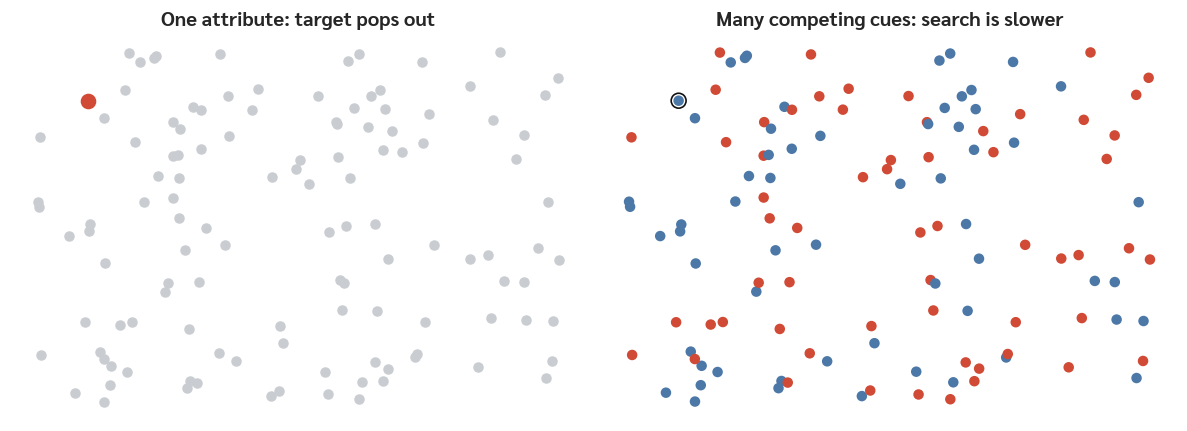

In [12]:
points = rng.uniform(0, 1, (120, 2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].scatter(points[:,0], points[:,1], color="#C9CDD1", s=28)
axes[0].scatter(points[73,0], points[73,1], color="#D04A35", s=70)
axes[0].set_title("One attribute: target pops out")
alternating = np.where(np.arange(len(points)) % 2 == 0, "#D04A35", "#4C78A8")
axes[1].scatter(points[:,0], points[:,1], c=alternating, s=28,
                marker="o")
axes[1].scatter(points[73,0], points[73,1], facecolors="none", edgecolors="#111", s=80)
axes[1].set_title("Many competing cues: search is slower")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.spines[:].set_visible(False)
fig.tight_layout(); plt.show()

### Colormap ต้องตรงชนิดข้อมูลและการรับรู้

rainbow/jet เปลี่ยนความสว่างไม่สม่ำเสมอ จึงสร้างขอบที่ดูเหมือนมีอยู่ในข้อมูล ส่วน viridis เปลี่ยนความสว่าง
ต่อเนื่องกว่าและยังรักษาลำดับเมื่อมองเป็นขาวดำ ใช้ sequential map กับค่าต่ำ→สูง, diverging map เมื่อมี
จุดกึ่งกลางที่มีความหมาย และ categorical palette กับกลุ่มที่ไม่มีลำดับ

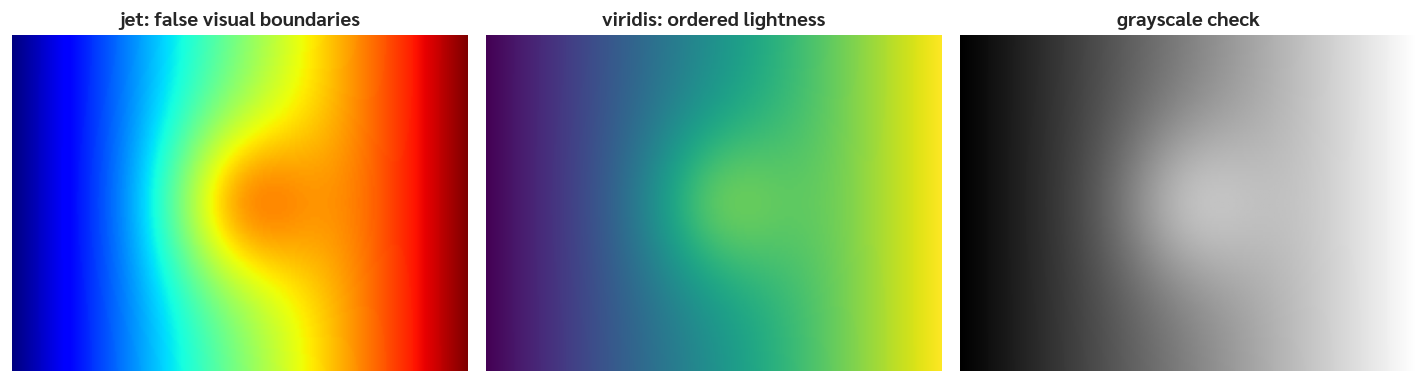

In [13]:
gx, gy = np.meshgrid(np.linspace(-3, 3, 240), np.linspace(-2, 2, 120))
surface = gx + 1.4*np.exp(-(gx**2 + gy**2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].imshow(surface, cmap="jet", aspect="auto"); axes[0].set_title("jet: false visual boundaries")
axes[1].imshow(surface, cmap="viridis", aspect="auto"); axes[1].set_title("viridis: ordered lightness")
axes[2].imshow(surface, cmap="gray", aspect="auto"); axes[2].set_title("grayscale check")
for ax in axes: ax.set_axis_off()
fig.tight_layout(); plt.show()

### สีควรมีหน้าที่

ตัวอย่างนี้ใช้สีแดงเน้นวิธี Proposed แต่ยังใช้รูปแบบเส้นและ marker ซ้ำอีกชั้นหนึ่ง เพื่อให้แยก series
ได้เมื่อพิมพ์ขาวดำหรือเมื่อผู้ชมมองสีบางคู่ได้ยาก สีจึงทำหน้าที่เน้น ไม่ใช่เป็นข้อมูลเพียงช่องทางเดียว

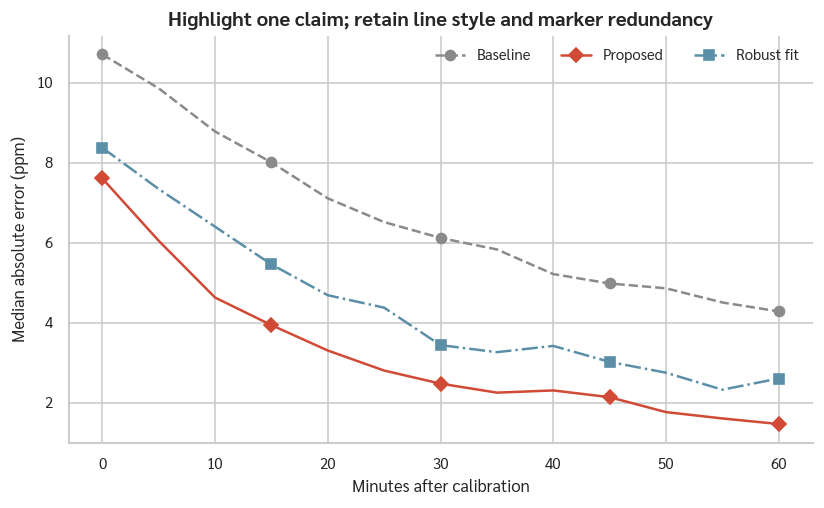

In [14]:
# Color should carry a purpose and should not be the only carrier of meaning.
color_demo = sensor_df.groupby(["method", "minute"], as_index=False)["error_ppm"].median()
fig, ax = plt.subplots(figsize=(8, 4.4))
styles = {
    "Baseline": ("#8A8A8A", "--", "o"),
    "Robust fit": ("#5B8FA8", "-.", "s"),
    "Proposed": ("#D04A35", "-", "D"),
}
for method, part in color_demo.groupby("method"):
    color, ls, marker = styles[method]
    ax.plot(part["minute"], part["error_ppm"], label=method,
            color=color, ls=ls, marker=marker, markevery=3)
ax.set(title="Highlight one claim; retain line style and marker redundancy",
       xlabel="Minutes after calibration", ylabel="Median absolute error (ppm)")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. แสดงความไม่แน่นอนให้ตรงความหมาย

SD, SE, confidence interval, prediction interval และ quantile interval ตอบคนละคำถาม
ห้ามเลือกเพียงเพราะ “เป็น error bar” เหมือนกัน ตัวอย่างต่อไปใช้ median กับช่วง 25–75%
เพื่อบรรยายความแปรปรวนของ repeated runs ไม่ใช่ CI ของค่าเฉลี่ย

In [15]:
plot_df = (
    sensor_df.groupby(["method", "minute"])["error_ppm"]
    .agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n="size")
    .reset_index()
)
plot_df.head()

,method,minute,median,q25,q75,n
0,Baseline,0,10.711111,10.369762,11.307295,24
1,Baseline,5,9.863469,9.349310,10.468478,24
2,Baseline,10,8.782864,8.357807,9.465177,24
3,Baseline,15,8.011802,7.643048,8.509643,24
4,Baseline,20,7.110991,6.453394,7.687182,24


### เส้นกลางและแถบเงาตอบคนละคำถาม

เส้นแสดง median ของ repeated runs ส่วนแถบเงาแสดงช่วง 25–75% ของข้อมูลดิบในแต่ละเวลา
แถบนี้บอกการกระจายของ runs ไม่ใช่ confidence interval และไม่ควรถูกตีความว่าเป็นความน่าจะเป็น
ที่ค่าจริงจะอยู่ในแถบ

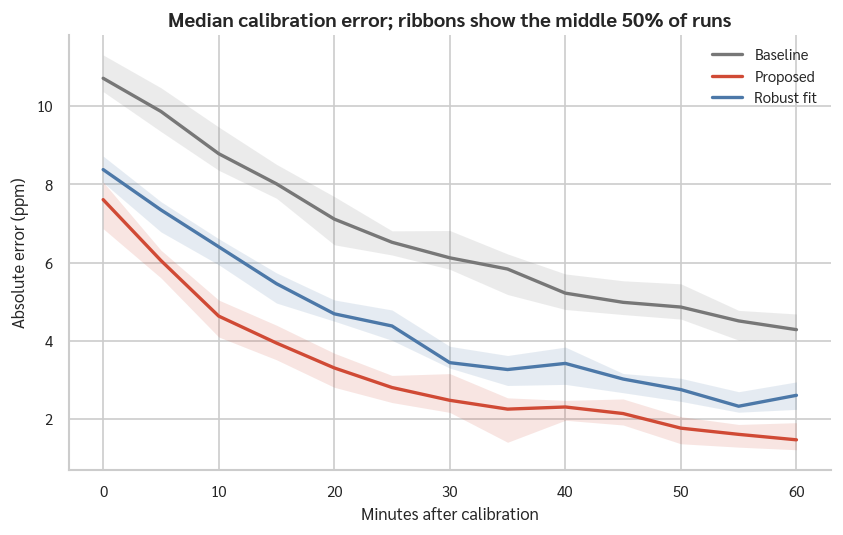

In [16]:
fig, ax = plt.subplots(figsize=(8.2, 4.7))
palette = {"Baseline": "#777777", "Robust fit": "#4C78A8", "Proposed": "#D04A35"}
for method, part in plot_df.groupby("method", sort=False):
    ax.plot(part["minute"], part["median"], color=palette[method], label=method, lw=2)
    ax.fill_between(part["minute"], part["q25"], part["q75"],
                    color=palette[method], alpha=.14, linewidth=0)
ax.set(title="Median calibration error; ribbons show the middle 50% of runs",
       xlabel="Minutes after calibration", ylabel="Absolute error (ppm)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### สิ่งที่ถูกตัดออกอาจเปลี่ยนการตัดสินใจ

กรณีจำลองต่อไปเลียนแบบปัญหาทั่วไปในงาน safety: หากดูเฉพาะรอบที่เกิด failure เราไม่เห็นฐานเปรียบเทียบ
และประเมินความสัมพันธ์กับอุณหภูมิไม่ได้ ต้องแสดงทั้งรอบที่เกิดและไม่เกิดเหตุ พร้อมอธิบายกฎคัดข้อมูล

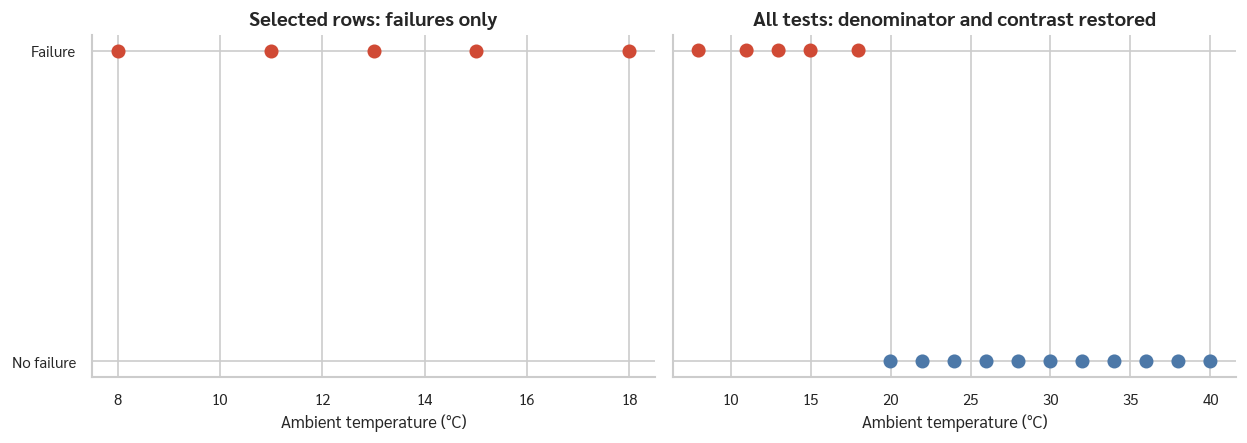

In [17]:
temperatures = np.array([8, 11, 13, 15, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40])
failure_prob = 1 / (1 + np.exp((temperatures - 20) / 3.2))
failures = rng.binomial(1, failure_prob)
safety_df = pd.DataFrame({"temperature_c": temperatures, "failure": failures})
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
failed = safety_df.query("failure == 1")
axes[0].scatter(failed["temperature_c"], failed["failure"], color="#D04A35", s=55)
axes[0].set_title("Selected rows: failures only")
axes[1].scatter(safety_df["temperature_c"], safety_df["failure"],
                c=safety_df["failure"].map({0:"#4C78A8", 1:"#D04A35"}), s=55)
axes[1].set_title("All tests: denominator and contrast restored")
for ax in axes:
    ax.set(xlabel="Ambient temperature (°C)", yticks=[0,1], yticklabels=["No failure","Failure"])
    ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); plt.show()

### ความซื่อสัตย์ไม่เท่ากับการบังคับทุกแกนให้เริ่มศูนย์

bar chart อาศัยความยาวจึงควรเริ่มจากศูนย์ แต่ point/line chart สามารถซูมช่วงที่มีความหมายได้ หากระบุ scale
ชัด แสดง uncertainty และไม่ซ่อนบริบท การตัดสินต้องพิจารณางานอ่านค่าและนัยสำคัญทางสาขา ไม่ใช้กฎรูปแบบ
แทนเหตุผลทางวิทยาศาสตร์

## 4. กราฟที่รันได้ แต่ยังใช้ไม่ได้

กราฟอาจสร้างจากโค้ดที่ไม่มี error และใช้ตัวเลขจริงทุกค่า แต่ยังทำให้ผู้อ่านเข้าใจผิดได้จาก baseline,
scale, window, denominator หรือการวางหลาย panel ตัวอย่างต่อไปแยกปัญหาเหล่านี้ทีละแบบ

### กรณีที่ 1 — แกนตั้งเริ่มตรงไหน

bar chart ใช้ความยาวจาก baseline เป็นตัวสื่อขนาด การตัดแกนตั้งจึงทำให้ความต่าง 4 คะแนนดูใหญ่ขึ้นมาก
ภาพคู่ต่อไปใช้ข้อมูลเดียวกัน เพื่อให้เห็นว่าการกำหนดช่วงแกนเปลี่ยนความรู้สึกได้อย่างไร

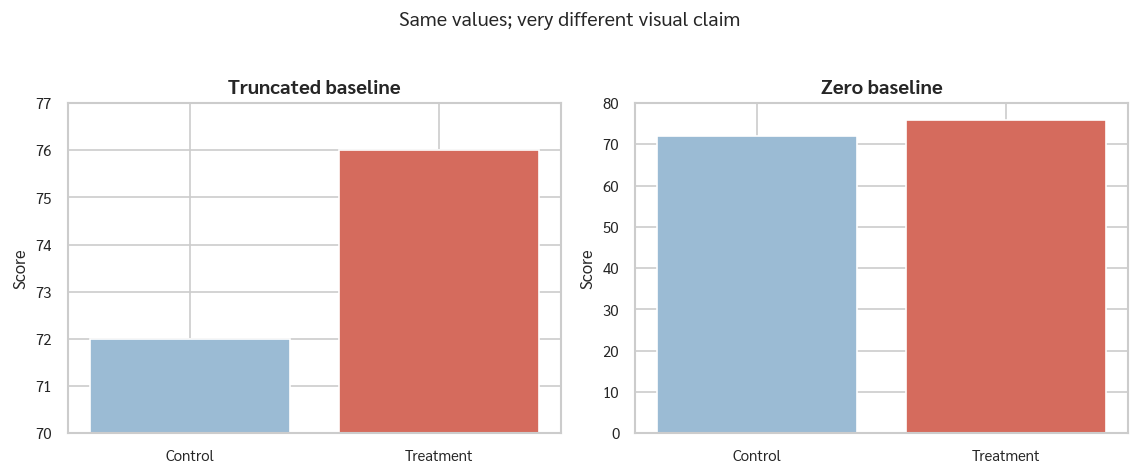

In [18]:
# Pitfall 1: a truncated baseline exaggerates a modest difference.
means = pd.Series({"Control": 72, "Treatment": 76})
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharex=True)
for ax, ylim, title in zip(axes, [(70, 77), (0, 80)], ["Truncated baseline", "Zero baseline"]):
    ax.bar(means.index, means.values, color=["#9BBBD4", "#D56B5D"])
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.set_ylabel("Score")
fig.suptitle("Same values; very different visual claim", y=1.03)
fig.tight_layout()
plt.show()

### กรณีที่ 2 — แกนตั้งสองข้าง

dual-axis chart วางตัวแปรคนละหน่วยไว้ในพื้นที่เดียวกัน รูปร่างของเส้นสามารถดูสัมพันธ์กันมากหรือน้อย
ได้เพียงเปลี่ยนช่วงแกน จึงต้องมีเหตุผลชัดเจน หรือแยกเป็นสอง panel ที่ใช้แกนเวลาเดียวกัน

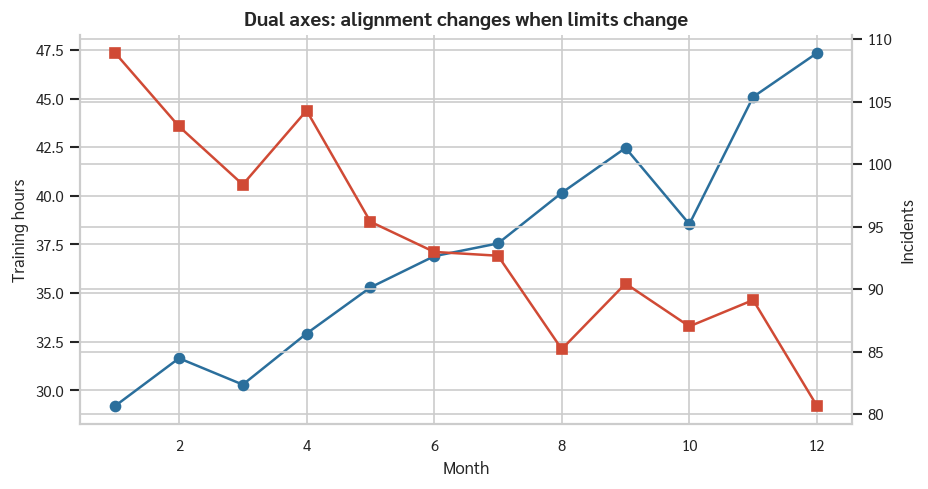

In [19]:
# Pitfall 2: dual axes can manufacture a visual relationship by rescaling.
month = np.arange(1, 13)
training = 28 + 1.5 * month + rng.normal(0, 1.2, 12)
incidents = 110 - 2.5 * month + rng.normal(0, 5, 12)
fig, ax1 = plt.subplots(figsize=(8.3, 4.2))
ax2 = ax1.twinx()
ax1.plot(month, training, color="#2B6F9C", marker="o")
ax2.plot(month, incidents, color="#D04A35", marker="s")
ax1.set(xlabel="Month", ylabel="Training hours", title="Dual axes: alignment changes when limits change")
ax2.set_ylabel("Incidents")
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
plt.show()

### กรณีที่ 3 — ช่วงเวลาที่เลือกและค่ cumulative

การเลือกเฉพาะช่วงที่เพิ่มขึ้นทำให้ไม่เห็นจุดกลับตัว ขณะที่ค่าคumulative มักเพิ่มต่อไปแม้ค่ารายปีลดลง
ก่อนสรุปแนวโน้มจึงต้องถามทั้งช่วงเวลาและนิยามของค่าที่อยู่บนแกนตั้ง

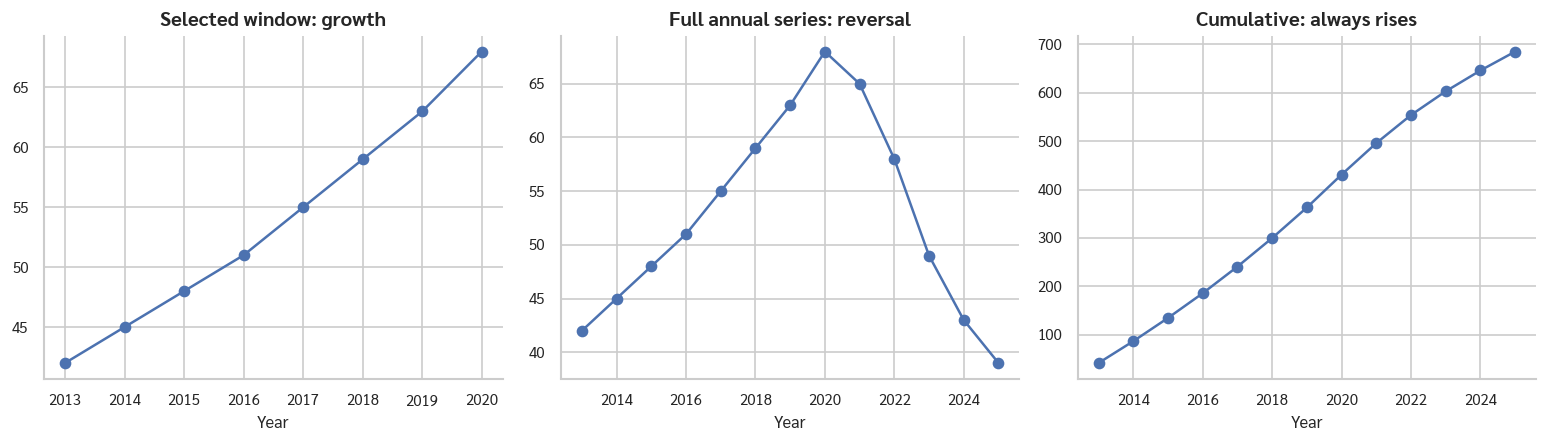

In [20]:
# Pitfall 3: a selected time window and a cumulative view can hide reversal.
year = np.arange(2013, 2026)
annual = np.array([42, 45, 48, 51, 55, 59, 63, 68, 65, 58, 49, 43, 39])
trend_df = pd.DataFrame({"year": year, "annual": annual})
trend_df["cumulative"] = trend_df["annual"].cumsum()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(year[:8], annual[:8], marker="o")
axes[0].set_title("Selected window: growth")
axes[1].plot(year, annual, marker="o")
axes[1].set_title("Full annual series: reversal")
axes[2].plot(year, trend_df["cumulative"], marker="o")
axes[2].set_title("Cumulative: always rises")
for ax in axes:
    ax.set_xlabel("Year")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### กรณีที่ 4 — หลาย panel แต่ฐานเปรียบเทียบไม่เหมือนกัน

layout และสีที่เหมือนกันทำให้สมองอยากเทียบความสูงข้าม panel แต่สามภาพนี้ใช้ count, proportion
และ rate ต่อ 1,000 คนต่างกัน ปัญหาจึงอยู่ที่ denominator และหน่วย ไม่ใช่เพียงรูปแบบกราฟ

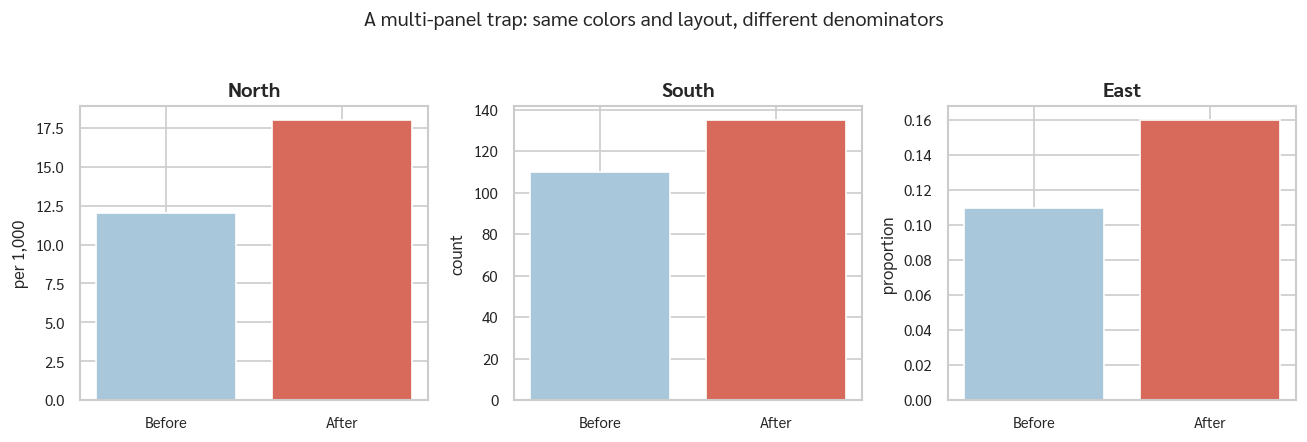

In [21]:
# Pitfall 4: each panel is individually legal, but the collection is inconsistent.
panel = pd.DataFrame({
    "site": np.repeat(["North", "South", "East"], 2),
    "group": ["Before", "After"] * 3,
    "rate": [12, 18, 110, 135, .11, .16],
})
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
units = ["per 1,000", "count", "proportion"]
for ax, (site, part), unit in zip(axes, panel.groupby("site", sort=False), units):
    ax.bar(part["group"], part["rate"], color=["#A9C7DA", "#D86A5B"])
    ax.set_title(site)
    ax.set_ylabel(unit)
fig.suptitle("A multi-panel trap: same colors and layout, different denominators", y=1.04)
fig.tight_layout()
plt.show()

### คำตอบที่ดีไม่ใช่ “กราฟนี้หลอก” อย่างเดียว

ต้องชี้ให้ได้ว่า **อะไร** ทำให้เทียบผิด เช่น baseline, scale, window, denominator,
aggregation หรือ visual hierarchy และระบุข้อมูลที่ต้องขอก่อนแก้ โดยเฉพาะกราฟหลาย panel:
ความสม่ำเสมอของหน่วยและ denominator สำคัญกว่าความสม่ำเสมอของสี